# **Importación de Librerias y Semillas**

In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.integrate import solve_ivp
from scipy.stats import pearsonr, spearmanr
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import norm as sparse_norm

SEED = 42
rng = np.random.default_rng(SEED)

FIG_DIR = Path("figuras")
RES_DIR = Path("results")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 100)

# **Modelo matemático**

Para $i=0,\ldots,N-1$:

$$
\dot x_i=-x_i^3-2x_i^2+1-z_i+I_i,\\
\dot z_i=
\frac1{\tau_0}
\left[
h_i(x_i)-z_i-K\sum_jA_{ij}(x_j-x_i)
\right],
$$


$$
h_i(x)=x_{0,i}-3+
\frac{3}{1+\exp(-(x-0.5)/0.1)}.
$$


$$
\tau_0=2857,\qquad I_i=3.1.
$$

El valor $x_0\approx2.91$ se usa únicamente como referencia para etiquetar la epileptogenidad.


# **Parámetros**

In [ ]:
TAU0 = 2857.0
I_DEFAULT = 3.1
X0_REFERENCE = 2.91

# **Elementos Básicos**

In [ ]:
def sigmoid_stable(u):
    u = np.asarray(u)
    out = np.empty_like(u, dtype=float)
    pos = u >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-u[pos]))
    eu = np.exp(u[~pos])
    out[~pos] = eu / (1.0 + eu)
    return out

def h_i(x, x0_i):
    return x0_i - 3.0 + 3.0 * sigmoid_stable((np.asarray(x) - 0.5) / 0.1)

def generate_x0(N=10, seed=42):
    if N < 2:
        raise ValueError("N debe ser >= 2.")
    local_rng = np.random.default_rng(seed)
    x0 = local_rng.normal(2.5, 0.5, N)
    x0[0] = 2.3
    x0[1] = 2.4
    if N > 2:
        x0[2:] = local_rng.uniform(2.9, 3.5, N - 2)
    return x0

N = 10
x0 = generate_x0(N, SEED)
I_vec = np.full(N, I_DEFAULT)

#  **Construcción del grafo**

La definición solicitada de la matriz de adyacencia es para este caso:

$$
A_{ij}=
\begin{cases}
1,&x_{0,j}<x_{0,i}\text{ e }i\neq j,\\
0,&\text{en otro caso}.
\end{cases}
$$



# **Construcción de la Matriz de Adyacencia y el Grafo**

In [ ]:
def build_adjacency(x0):
    x0 = np.asarray(x0, dtype=float)
    A = ((x0[None, :] < x0[:, None]) & ~np.eye(len(x0), dtype=bool)).astype(int)
    return A

def build_graph(A):
    return nx.DiGraph(np.asarray(A))

A = build_adjacency(x0)
G = build_graph(A)

print("A =")
print(A)
print("\nAristas de nx.DiGraph(A):")
print(list(G.edges()))


A =
[[0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 1 0 1]
 [1 1 1 0 1 1 1 1 1 1]
 [1 1 1 0 0 0 1 1 1 1]
 [1 1 1 0 1 0 1 1 1 1]
 [1 1 1 0 0 0 0 1 0 1]
 [1 1 0 0 0 0 0 0 0 1]
 [1 1 1 0 0 0 1 1 0 1]
 [1 1 0 0 0 0 0 0 0 0]]

Aristas de nx.DiGraph(A):
[(1, 0), (2, 0), (2, 1), (2, 7), (2, 9), (3, 0), (3, 1), (3, 2), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), (4, 0), (4, 1), (4, 2), (4, 6), (4, 7), (4, 8), (4, 9), (5, 0), (5, 1), (5, 2), (5, 4), (5, 6), (5, 7), (5, 8), (5, 9), (6, 0), (6, 1), (6, 2), (6, 7), (6, 9), (7, 0), (7, 1), (7, 9), (8, 0), (8, 1), (8, 2), (8, 6), (8, 7), (8, 9), (9, 0), (9, 1)]


# 3. Verificación obligatoria de la convención de dirección

Para `nx.DiGraph(A)`, una entrada $$A_{ij}=1$$ genera la arista

$$
i\rightarrow j.
$$

Sin embargo, en el término dinámico

$$
\sum_j A_{ij}(x_j-x_i),
$$

el estado $x_j\$ aparece en la ecuación de $i$. Por tanto, **desde la interpretación dinámica**, $j$ es quien influye sobre $i$.

Así, la arista de NetworkX $i\to j$ no coincide directamente con la flecha "influencia $j\to i$" asociada al término dinámico. Por eso se deben conservar y comparar ambas convenciones:

- $A$:  Definición original + representación literal en NetworkX.
- $A^T$:  Convención transpuesta, útil si se desea que una arista $j \to i$ represente que $j$ influye sobre $i$.


# **Ejemplo**

In [ ]:
x0_demo = np.array([2.3, 2.4, 3.1])
A_demo = build_adjacency(x0_demo)
G_demo = build_graph(A_demo)

print("x0_demo =", x0_demo)
print("\nA_demo =")
print(A_demo)

print("\nAristas de nx.DiGraph(A_demo):")
for u, v in G_demo.edges():
    print(f"{u} -> {v}   (NetworkX)")

print("\nInterpretación del término dinámico A_ij(x_j-x_i):")
for i in range(len(x0_demo)):
    js = np.where(A_demo[i] == 1)[0]
    print(f"Ecuación de i={i}: recibe términos desde j={list(js)}")

print("\nMatriz transpuesta A_demo.T =")
print(A_demo.T)


x0_demo = [2.3 2.4 3.1]

A_demo =
[[0 0 0]
 [1 0 0]
 [1 1 0]]

Aristas de nx.DiGraph(A_demo):
1 -> 0   (NetworkX)
2 -> 0   (NetworkX)
2 -> 1   (NetworkX)

Interpretación del término dinámico A_ij(x_j-x_i):
Ecuación de i=0: recibe términos desde j=[]
Ecuación de i=1: recibe términos desde j=[np.int64(0)]
Ecuación de i=2: recibe términos desde j=[np.int64(0), np.int64(1)]

Matriz transpuesta A_demo.T =
[[0 1 1]
 [0 0 1]
 [0 0 0]]


### Test conceptual de la dirección

Para $x_0=(2.3,2.4,3.1)$:

- la región 2 tiene el mayor $x_0$;
- $A_{2,0}=A_{2,1}=1$;
- `nx.DiGraph(A)` Dibuja $2\to0$ y $2\to1$;
- pero en la ecuación de la región 2 aparecen $x_0$ y $x_1$.

Por lo tanto, si las flechas se interpretan como **influencia dinámica**, la convención natural asociada al término es la transpuesta.


# **Visualización del grafo estructural**

## **Rojo**: $x_{0,i}<2.91$ Epileptogénico.

## **Azul**: $x_{0,i}\ge2.91$. Sano

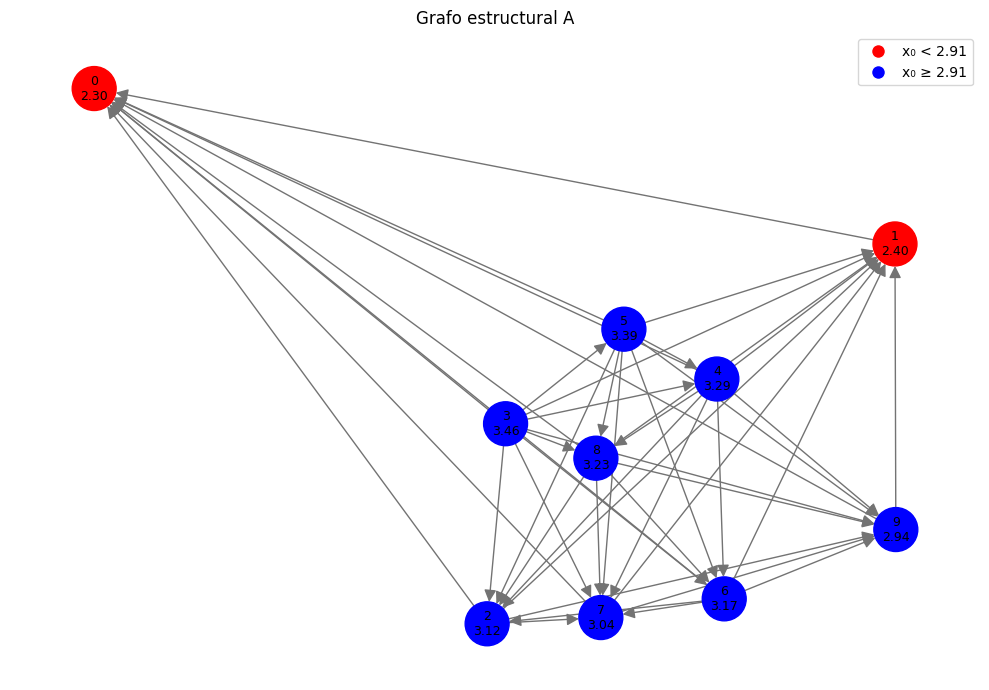

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': 'Grafo estructural A'}>)

In [ ]:
def plot_structural_graph(A, x0, filename=FIG_DIR/"grafo.png", title=None):
    G = build_graph(A)
    pos = nx.spring_layout(G, seed=42)

    colors = ['red' if x < X0_REFERENCE else 'blue' for x in x0]
    labels = {i: f"{i}\n{x0[i]:.2f}" for i in range(len(x0))}

    fig, ax = plt.subplots(figsize=(10, 7))
    nx.draw_networkx(
        G, pos=pos, ax=ax,
        node_color=colors,
        labels=labels,
        arrows=True,
        node_size=1000,
        arrowsize=18,
        edge_color="0.45",
        font_size=9
    )
    ax.set_title(title or "Grafo estructural A")
    ax.axis("off")

    from matplotlib.lines import Line2D
    legend = [
        Line2D([0], [0], marker='o', color='w', label='x₀ < 2.91',
               markerfacecolor='red', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='x₀ ≥ 2.91',
               markerfacecolor='blue', markersize=10)
    ]
    ax.legend(handles=legend, loc="best")
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    return fig, ax

plot_structural_graph(A, x0)


# **Métricas topológicas**

## Se calculan
$$
d_i^{out},  d_i^{in}, C_B(i).
$$


In [ ]:
def graph_metrics(G):
    metrics = pd.DataFrame(index=sorted(G.nodes()))
    metrics.index.name = "node"

    metrics["out_degree"] = pd.Series(dict(G.out_degree()))
    metrics["in_degree"] = pd.Series(dict(G.in_degree()))
    metrics["betweenness"] = pd.Series(nx.betweenness_centrality(G))
    metrics["clustering"] = pd.Series(nx.clustering(G))

    scc = list(nx.strongly_connected_components(G))
    metrics["scc_id"] = -1
    for k, comp in enumerate(scc):
        for node in comp:
            metrics.loc[node, "scc_id"] = k

    if nx.is_strongly_connected(G):
        metrics.attrs["average_shortest_path_length"] = nx.average_shortest_path_length(G)
    else:
        metrics.attrs["average_shortest_path_length"] = None

    return metrics

topology = graph_metrics(G)
display(topology)

if topology.attrs["average_shortest_path_length"] is None:
    print("El grafo no es fuertemente conexo: no se fuerza la longitud media dirigida.")
    print("Se reportan componentes fuertemente conexas y se puede estudiar el grafo subyacente no dirigido.")
else:
    print("Average shortest path length:", topology.attrs["average_shortest_path_length"])


,out_degree,in_degree,betweenness,clustering,scc_id
node,,,,,
0,0,9,0.0,0.5,0
1,1,8,0.0,0.5,1
2,4,5,0.0,0.5,4
3,9,0,0.0,0.5,9
4,7,2,0.0,0.5,7
5,8,1,0.0,0.5,8
6,5,4,0.0,0.5,5
7,3,6,0.0,0.5,3
8,6,3,0.0,0.5,6


El grafo no es fuertemente conexo: no se fuerza la longitud media dirigida.
Se reportan componentes fuertemente conexas y se puede estudiar el grafo subyacente no dirigido.


# **Dinámica de los Epileptores**

## El estado completo para N epileptors es:

$
X=(x_0,\ldots,x_{N-1},z_0,\ldots,z_{N-1}).
$

## La implementación permite cambiar $A$, $K$, $I$, $\tau_0$, y usar $A^T$ sin modificar la definición original.


In [ ]:
def rhs(t, state, x0, A, K, tau0=TAU0, I=None):
    x0 = np.asarray(x0, dtype=float)
    A = np.asarray(A, dtype=float)
    N = len(x0)
    x = state[:N]
    z = state[N:]

    if I is None:
        I = np.full(N, I_DEFAULT)
    I = np.asarray(I, dtype=float)

    coupling = np.sum(A * (x[None, :] - x[:, None]), axis=1)
    dx = -x**3 - 2*x**2 + 1.0 - z + I
    dz = (h_i(x, x0) - z - K * coupling) / tau0

    return np.concatenate([dx, dz])

def validate_rhs_matrix_form(x, A):
    x = np.asarray(x)
    A = np.asarray(A)
    direct = np.sum(A * (x[None, :] - x[:, None]), axis=1)
    matrix_form = A @ x - np.sum(A, axis=1) * x
    return direct, matrix_form


## 7. Integración numérica y convergencia

Se utiliza `solve_ivp`, comenzando con `DOP853`.

La configuración numérica no debe determinar las conclusiones. Por ello se incluye una comparación de tolerancias y `max_step`.


In [ ]:
def simulate(
    x0, A, K,
    x_init=None, z_init=None,
    T=30000.0,
    n_samples=5000,
    method="DOP853",
    rtol=1e-8,
    atol=1e-10,
    max_step=np.inf,
    I=None,
    tau0=TAU0
):

    x0 = np.asarray(x0, dtype=float)
    N = len(x0)

    if x_init is None:
        x_init = np.full(N, -1.0)
    if z_init is None:
        z_init = np.zeros(N)

    y0 = np.concatenate([x_init, z_init])
    t_eval = np.linspace(0.0, T, n_samples)

    sol = solve_ivp(
        rhs, (0.0, T), y0,
        args=(x0, A, K, tau0, I),
        method=method,
        t_eval=t_eval,
        rtol=rtol,
        atol=atol,
        max_step=max_step
    )

    if not sol.success:
        warnings.warn(sol.message)

    N = len(x0)
    x = sol.y[:N]
    z = sol.y[N:]

    return sol.t, x, z, sol

t_test, x_test, z_test, sol_test = simulate(
    x0, A, K=0.0, T=500.0, n_samples=1000, max_step=50.0
)
print("success:", sol_test.success)
print("nfev:", sol_test.nfev)


success: True
nfev: 9968


In [ ]:
# Test 5: implementación directa vs forma matricial
x_random = rng.normal(size=N)
direct, matrix_form = validate_rhs_matrix_form(x_random, A)
assert np.allclose(direct, matrix_form), "Falló la equivalencia del término de acoplamiento."

# Test 4: A=0 desacopla las ecuaciones
zero_A = np.zeros_like(A)
state_random = rng.normal(size=2*N)
r0 = rhs(0.0, state_random, x0, zero_A, K=3.0)
r0_again = rhs(0.0, state_random, x0, zero_A, K=0.0)
assert np.allclose(r0, r0_again), "A=0 no desacopló correctamente el término de red."

# Test 1 y 2
assert np.all(np.diag(A) == 0), "A_ii debe ser 0."
for i in range(N):
    for j in range(N):
        expected = int(i != j and x0[j] < x0[i])
        assert A[i, j] == expected

print("Todos los tests algebraicos básicos pasaron.")


Todos los tests algebraicos básicos pasaron.


# 8. Condiciones iniciales

Se implementan los tres experimentos pedidos:

- **A — homogéneas**

$$
x_i(0)=x_0^{init},\qquad z_i(0)=z_0^{init}.
$$

- **B — Pequeñas perturbaciones**

$$
x_i(0)=x^{init}+\epsilon_i,\qquad z_i(0)=z^{init}+\eta_i.
$$
- **C — aleatorias**

Condiciones iniciales aleatorias dentro de una región configurable.


In [ ]:
def initial_conditions(N, experiment="A", seed=42,
                        x_init=-1.0, z_init=0.0,
                        perturbation_scale=1e-2):
    local_rng = np.random.default_rng(seed)

    if experiment == "A":
        x = np.full(N, x_init)
        z = np.full(N, z_init)

    elif experiment == "B":
        x = np.full(N, x_init) + local_rng.normal(0, perturbation_scale, N)
        z = np.full(N, z_init) + local_rng.normal(0, perturbation_scale, N)

    elif experiment == "C":
        x = local_rng.uniform(-2.0, 2.0, N)
        z = local_rng.uniform(-1.0, 1.0, N)

    else:
        raise ValueError("experiment debe ser A, B o C")

    return x, z

x_init_A, z_init_A = initial_conditions(N, "A", SEED)
x_init_B, z_init_B = initial_conditions(N, "B", SEED)
x_init_C, z_init_C = initial_conditions(N, "C", SEED)

print("A:", x_init_A[:3], z_init_A[:3])
print("B:", x_init_B[:3], z_init_B[:3])
print("C:", x_init_C[:3], z_init_C[:3])


A: [-1. -1. -1.] [0. 0. 0.]
B: [-0.997  -1.0104 -0.9925] [0.0088 0.0078 0.0007]
C: [ 1.0958 -0.2445  1.4344] [-0.2584  0.8535  0.2877]


# 9. Series temporales y actividad colectiva

Se definen

$$
m_N(t)=\frac1N\sum_i x_i(t) \qquad (\text{Campo Medio})
$$

$$
m_{\rm epi}(t)=\frac{x_0(t)+x_1(t)}2,
$$

$$
m_{\rm sano}(t)=\frac1{N-2}\sum_{i=2}^{N-1}x_i(t).
$$

Las tres curvas permiten comparar la actividad de las regiones etiquetadas como epileptogénicas con las restantes.


In [ ]:
def collective_observables(x):
    N = x.shape[0]
    m_N = x.mean(axis=0)
    m_epi = x[:2].mean(axis=0)
    m_sano = x[2:].mean(axis=0) if N > 2 else np.full(x.shape[1], np.nan)
    return m_N, m_epi, m_sano

def plot_time_series(t, x, x0, filename_prefix="series"):
    N = x.shape[0]

    fig1, ax1 = plt.subplots(figsize=(12, 5))
    for i in range(min(2, N)):
        ax1.plot(t, x[i], label=f"Región {i} (x₀={x0[i]:.2f})")
    ax1.set(xlabel="t", ylabel="x_i(t)", title="Regiones epileptogénicas")
    ax1.legend()
    fig1.tight_layout()
    fig1.savefig(FIG_DIR/f"{filename_prefix}_epi.png", dpi=200)
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(12, 5))
    for i in range(2, N):
        ax2.plot(t, x[i], alpha=0.7, label=f"Región {i}")
    ax2.set(xlabel="t", ylabel="x_i(t)", title="Regiones sanas")
    if N <= 15:
        ax2.legend(ncol=2)
    fig2.tight_layout()
    fig2.savefig(FIG_DIR/f"{filename_prefix}_sanas.png", dpi=200)
    plt.show()

    fig3, ax3 = plt.subplots(figsize=(12, 5))
    for i in range(N):
        ax3.plot(t, x[i], alpha=0.75, label=f"{i}")
    ax3.set(xlabel="t", ylabel="x_i(t)", title="Todas las regiones")
    if N <= 15:
        ax3.legend(ncol=2)
    fig3.tight_layout()
    fig3.savefig(FIG_DIR/f"{filename_prefix}_todas.png", dpi=200)
    plt.show()

def plot_collective_activity(t, x, filename="actividad_media.png"):
    m_N, m_epi, m_sano = collective_observables(x)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t, m_N, label=r"$m_N(t)$")
    ax.plot(t, m_epi, label=r"$m_{epi}(t)$")
    ax.plot(t, m_sano, label=r"$m_{sano}(t)$")
    ax.set(xlabel="t", ylabel="actividad media", title="Actividad colectiva")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

# **Simulación de las Regiones**

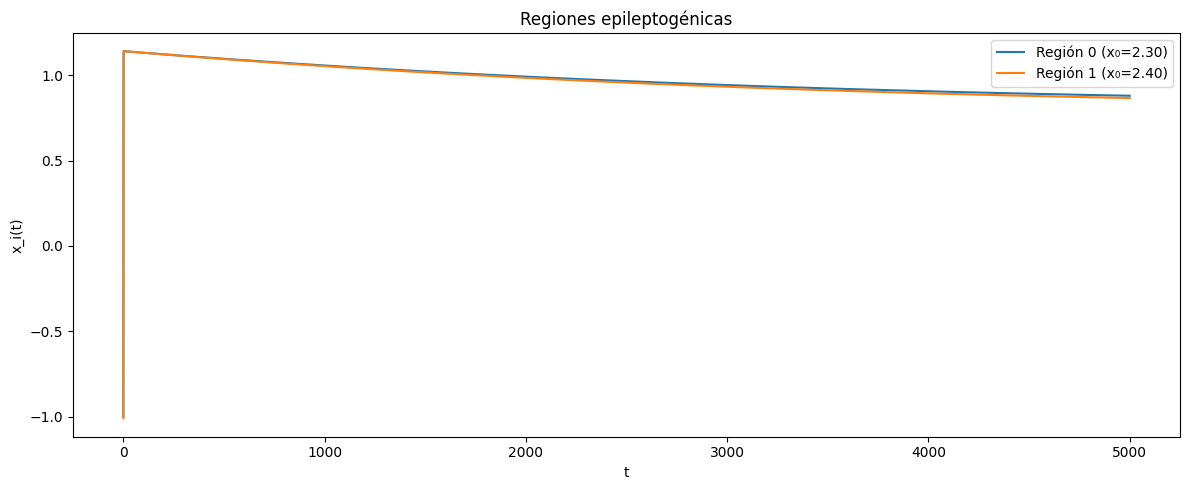

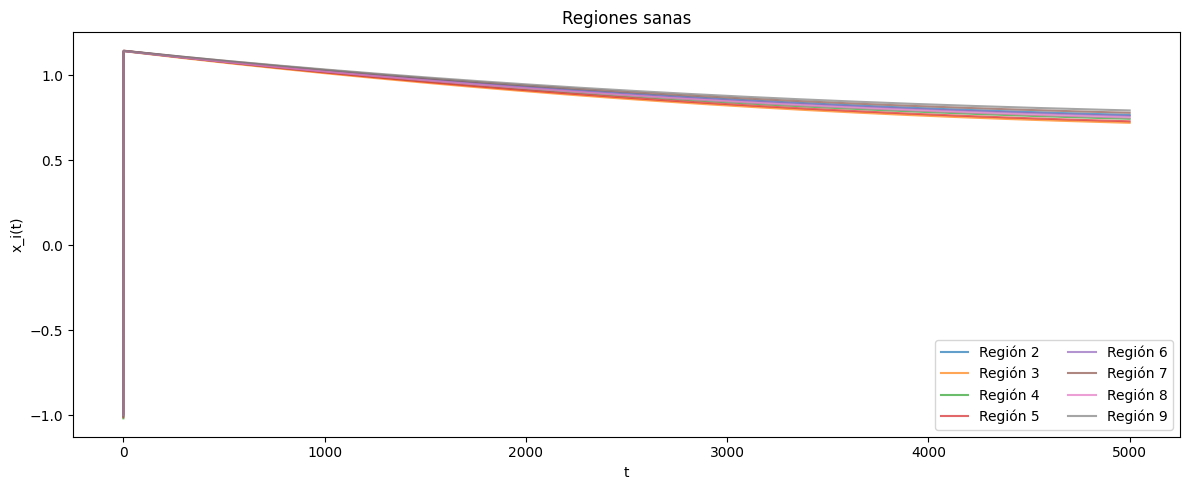

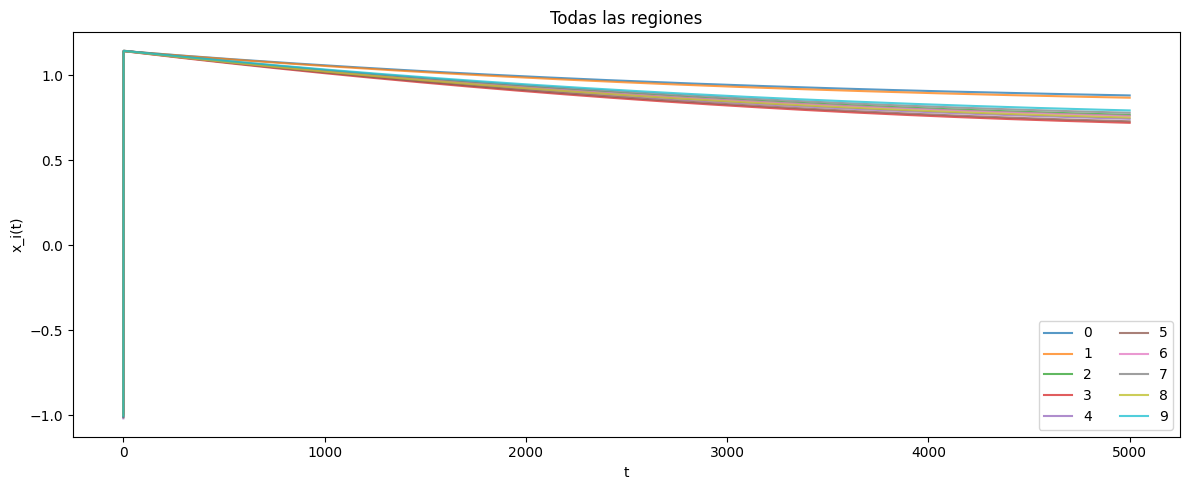

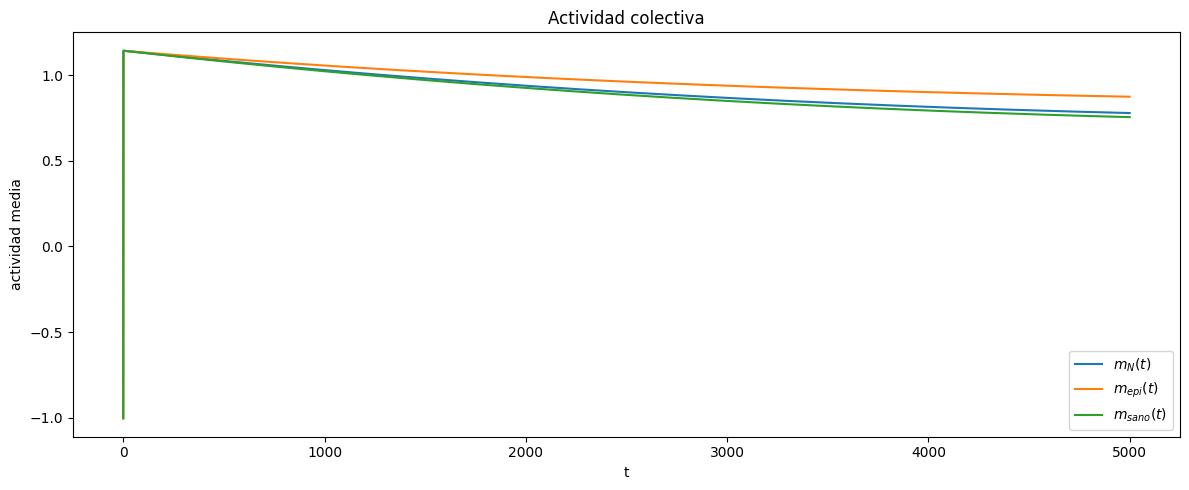

In [ ]:
BASE_K = 0.1
t, x, z, sol = simulate(
    x0, A, K=BASE_K,
    x_init=x_init_B, z_init=z_init_B,
    T=5000.0, n_samples=5000,
    method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
)

plot_time_series(t, x, x0)
plot_collective_activity(t, x)

# **Reclutamiento**

Se define

$$
T_i=\inf\{t:x_i(t)>x_{\rm th}
\text{ durante al menos }\Delta t\}.
$$

Los parámetros $x_{\rm th}$ y $\Delta t$ deben fijarse **antes de interpretar los resultados** y luego someterse a análisis de sensibilidad.




In [ ]:
def first_sustained_crossing(t, signal, threshold, min_duration):
    above = np.asarray(signal) > threshold
    if not np.any(above):
        return np.inf

    starts = np.where(above & ~np.r_[False, above[:-1]])[0]
    ends = np.where(~above & np.r_[False, above[:-1]])[0]

    if above[-1]:
        ends = np.r_[ends, len(above)]

    for s in starts:
        e_candidates = ends[ends > s]
        if len(e_candidates) == 0:
            continue
        e = e_candidates[0]
        if t[e-1] - t[s] >= min_duration:
            return float(t[s])

    return np.inf

def recruitment_times(t, x, threshold, min_duration):
    return np.array([
        first_sustained_crossing(t, x[i], threshold, min_duration)
        for i in range(x.shape[0])
    ])

X_THRESHOLD = 1.0
MIN_DURATION = 50.0

T_recruit = recruitment_times(t, x, X_THRESHOLD, MIN_DURATION)

order = np.argsort(T_recruit)
print("Secuencia de reclutamiento:")
for rank, i in enumerate(order, start=1):
    val = T_recruit[i]
    print(f"{rank:2d}. región {i}: T = {val if np.isfinite(val) else 'no reclutada'}")


Secuencia de reclutamiento:
 1. región 0: T = 1.0002000400080016
 2. región 1: T = 1.0002000400080016
 3. región 2: T = 1.0002000400080016
 4. región 3: T = 1.0002000400080016
 5. región 4: T = 1.0002000400080016
 6. región 5: T = 1.0002000400080016
 7. región 6: T = 1.0002000400080016
 8. región 7: T = 1.0002000400080016
 9. región 8: T = 1.0002000400080016
10. región 9: T = 1.0002000400080016


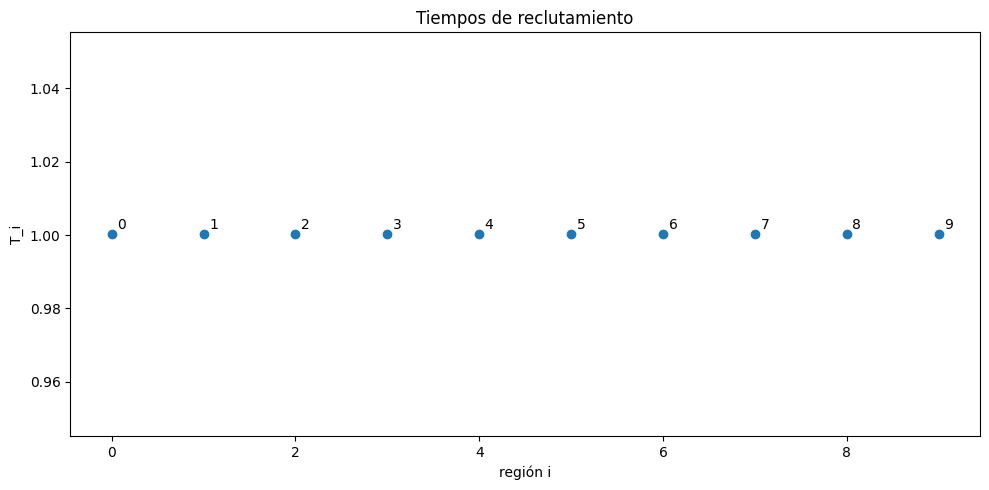

In [ ]:
def plot_recruitment_times(T_recruit, x0, filename="tiempos_reclutamiento.png"):
    fig, ax = plt.subplots(figsize=(10, 5))
    vals = np.where(np.isfinite(T_recruit), T_recruit, np.nan)
    ax.scatter(np.arange(len(vals)), vals)
    for i, Ti in enumerate(vals):
        if np.isfinite(Ti):
            ax.annotate(str(i), (i, Ti), xytext=(4, 4), textcoords="offset points")
    ax.set(xlabel="región i", ylabel="T_i", title="Tiempos de reclutamiento")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

plot_recruitment_times(T_recruit, x0)


# **Sensibilidad**  

In [ ]:
def recruitment_fraction(T_recruit, N):
    healthy = np.arange(2, N)
    recruited = np.isfinite(T_recruit[healthy])
    return recruited.mean() if len(healthy) else np.nan

thresholds = [0.5, 0.75, 1.0, 1.25, 1.5]
durations = [10, 25, 50, 100]

rows = []
for th in thresholds:
    for dur in durations:
        Ti = recruitment_times(t, x, th, dur)
        rows.append({
            "threshold": th,
            "min_duration": dur,
            "R": recruitment_fraction(Ti, N)
        })

sensitivity_recruitment = pd.DataFrame(rows)
display(sensitivity_recruitment.pivot(index="threshold", columns="min_duration", values="R"))


min_duration,10,25,50,100
threshold,,,,
0.50,1.0,1.0,1.0,1.0
0.75,1.0,1.0,1.0,1.0
1.00,1.0,1.0,1.0,1.0
1.25,0.0,0.0,0.0,0.0
1.50,0.0,0.0,0.0,0.0


# Mapa espacio-tiempo

Se construye

$$
X_{i,k}=x_i(t_k)
$$

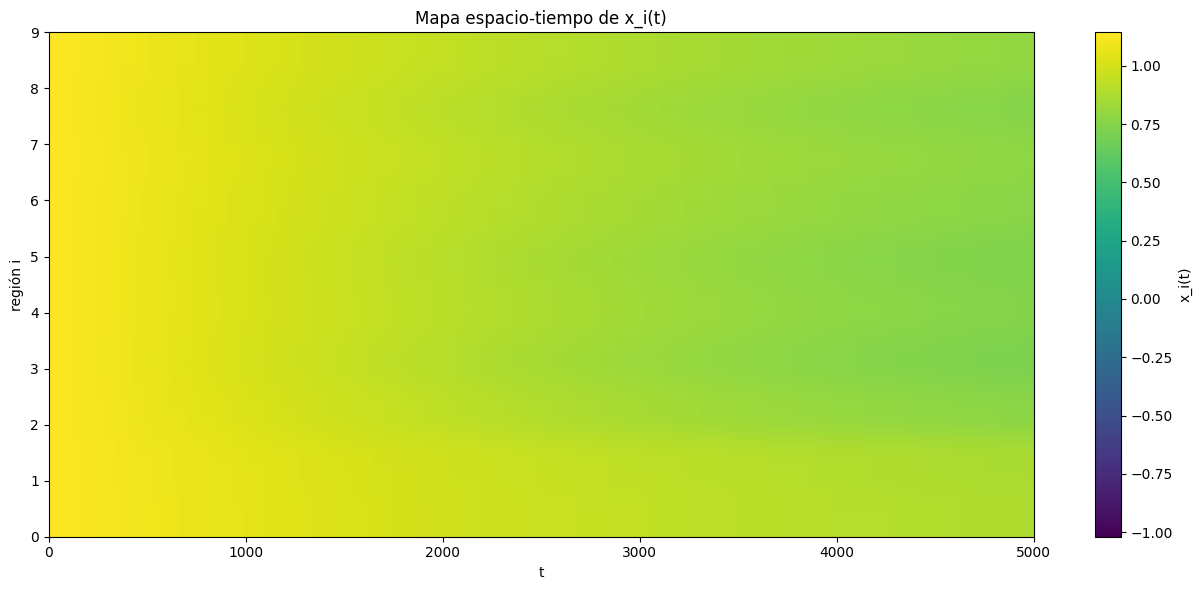

In [ ]:
def plot_spacetime(t, x, filename="mapa_espacio_tiempo.png"):
    fig, ax = plt.subplots(figsize=(13, 6))
    im = ax.imshow(
        x,
        aspect="auto",
        origin="lower",
        extent=[t[0], t[-1], 0, x.shape[0]-1]
    )
    ax.set(xlabel="t", ylabel="región i", title="Mapa espacio-tiempo de x_i(t)")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("x_i(t)")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200)
    plt.show()

plot_spacetime(t, x)


# **Grafo Dinámico**

Se define la intensidad:

$$
W^{(1)}_{ij}(t)=K A_{ij}|x_j(t)-x_i(t)|.
$$

También se conserva la versión con signo:

$$
W^{(2)}_{ij}(t)=K A_{ij}(x_j(t)-x_i(t)).
$$


In [ ]:
def dynamic_weight_matrices(x, A, K):
    A = np.asarray(A)
    diff = x[:, None, :] - x[None, :, :]  # [i,j,t] = x_j - x_i
    W_abs = K * A[:, :, None] * np.abs(diff)
    W_signed = K * A[:, :, None] * diff
    return np.moveaxis(W_abs, 2, 0), np.moveaxis(W_signed, 2, 0)

W_abs, W_signed = dynamic_weight_matrices(x, A, BASE_K)

print("Shape W_abs:", W_abs.shape, " = (tiempo, i, j)")


Shape W_abs: (5000, 10, 10)  = (tiempo, i, j)


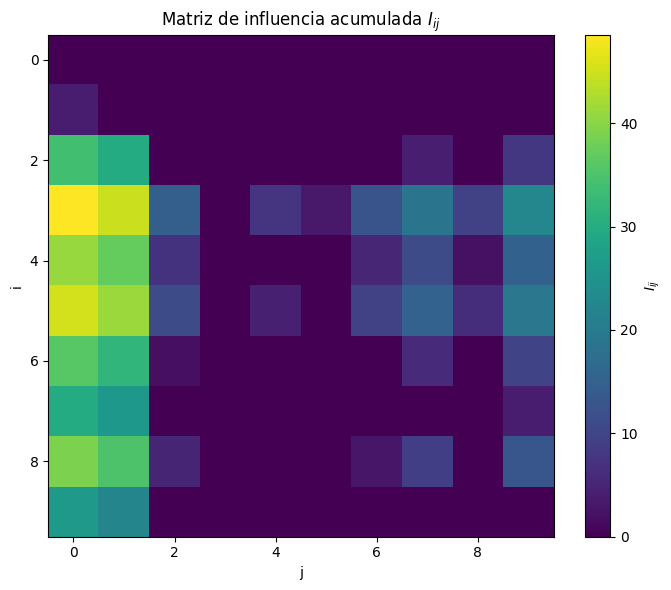

I_dyn =
[[ 0.      0.      0.      0.      0.      0.      0.      0.      0.
   0.    ]
 [ 3.9758  0.      0.      0.      0.      0.      0.      0.      0.
   0.    ]
 [33.9373 29.9629  0.      0.      0.      0.      0.      4.0373  0.
   7.9266]
 [48.5706 44.5965 14.6359  0.      7.4815  3.3173 12.6662 18.6733  9.6393
  22.5625]
 [41.0918 37.1162  7.1571  0.      0.      0.      5.1868 11.1934  2.1699
  15.0821]
 [45.264  41.2883 11.331   0.      4.2158  0.      9.3719 15.357   6.3828
  19.2504]
 [35.9056 31.931   1.9704  0.      0.      0.      0.      6.0071  0.
   9.8963]
 [29.913  25.9388  0.      0.      0.      0.      0.      0.      0.
   3.9162]
 [38.9316 34.9571  4.9974  0.      0.      0.      3.027   9.034   0.
  12.9232]
 [26.0137 22.0381  0.      0.      0.      0.      0.      0.      0.
   0.    ]]


In [ ]:
def cumulative_influence(t, W):
    return np.trapezoid(W, x=t, axis=0)

I_dyn = cumulative_influence(t, W_abs)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(I_dyn, origin="upper", aspect="auto")
ax.set(xlabel="j", ylabel="i", title=r"Matriz de influencia acumulada $I_{ij}$")
fig.colorbar(im, ax=ax, label=r"$I_{ij}$")
fig.tight_layout()
fig.savefig(FIG_DIR/"influencia_acumulada.png", dpi=200)
plt.show()

print("I_dyn =")
print(I_dyn)


# **Observaciones**: Esta matriz es muy importante, porque nos indica que regiones influyen sobre las otras en el tiempo.

#  **Grafo dinámico en distintos tiempos**

## Se representa $W_{ij}(t)$ como peso de las aristas.



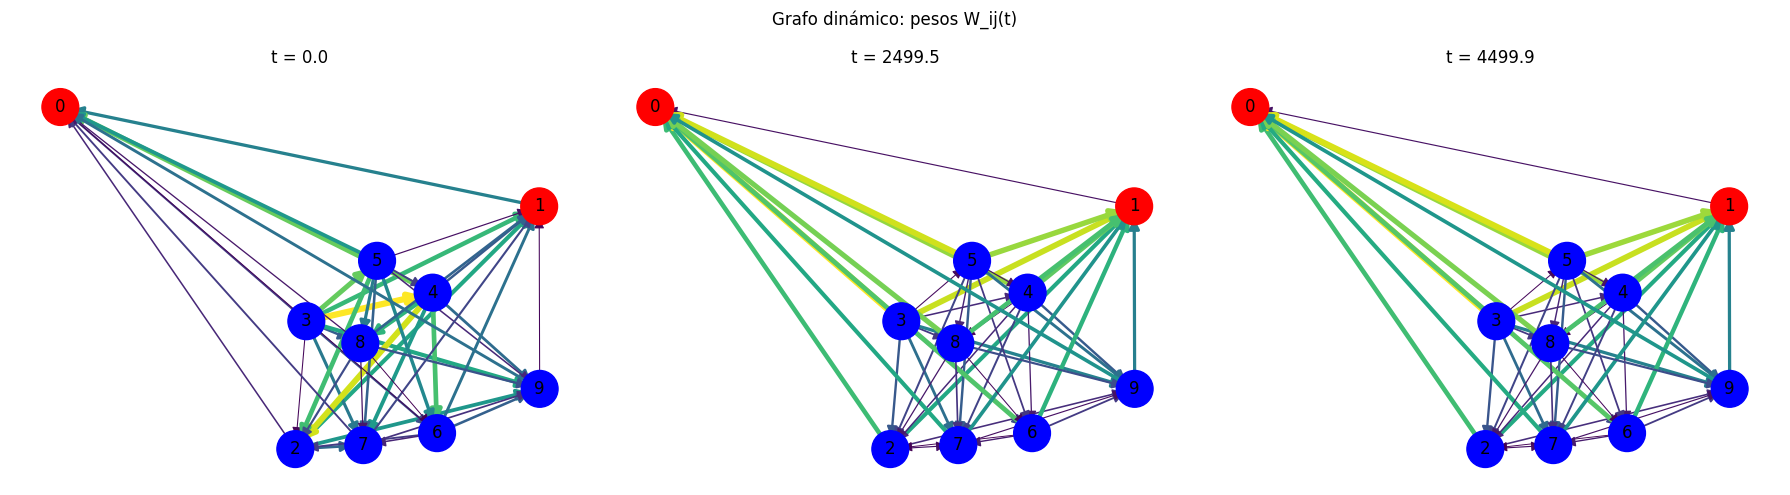

In [ ]:
def plot_dynamic_graph(A, x, t, W_abs, times=(0, 0.5, 0.9),
                          filename="grafo_dinamico.png"):
    G = build_graph(A)
    pos = nx.spring_layout(G, seed=42)

    indices = [min(int(frac*(len(t)-1)), len(t)-1) for frac in times]

    fig, axes = plt.subplots(1, len(indices), figsize=(6*len(indices), 5))
    if len(indices) == 1:
        axes = [axes]

    for ax, k in zip(axes, indices):
        weights = W_abs[k]
        edges = list(G.edges())

        if edges:
            vals = np.array([weights[u, v] for u, v in edges])
            vmax = vals.max() if vals.max() > 0 else 1.0
            widths = 0.5 + 4.0 * vals / vmax
        else:
            widths = []

        nx.draw_networkx_nodes(
            G, pos, ax=ax,
            node_color=['red' if xi < X0_REFERENCE else 'blue' for xi in x0],
            node_size=700
        )
        nx.draw_networkx_labels(G, pos, ax=ax)
        if edges:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=edges,
                width=widths, arrows=True, arrowsize=15,
                edge_color=vals
            )
        ax.set_title(f"t = {t[k]:.1f}")
        ax.axis("off")

    fig.suptitle("Grafo dinámico: pesos W_ij(t)")
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_dynamic_graph(A, x, t, W_abs)


# **Hubs dinámicos y comparación con estructura**

Se define

$$
H_i^{dyn,out}=\sum_j I_{ij},
\qquad
H_i^{dyn,in}=\sum_j I_{ji}.
$$

Se comparan con

$$
d_i^{out},\quad d_i^{in},\quad C_B(i).
$$




In [ ]:
H_dyn_out = I_dyn.sum(axis=1)
H_dyn_in = I_dyn.sum(axis=0)

analysis_df = topology.copy()
analysis_df["H_dyn_out"] = H_dyn_out
analysis_df["H_dyn_in"] = H_dyn_in
analysis_df["T_recruit"] = T_recruit
analysis_df["x0"] = x0
analysis_df["epileptogenic_label"] = x0 < X0_REFERENCE

display(analysis_df)

def safe_corr(x, y, method="pearson"):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3 or np.std(x[mask]) == 0 or np.std(y[mask]) == 0:
        return np.nan, np.nan
    if method == "spearman":
        return spearmanr(x[mask], y[mask])
    return pearsonr(x[mask], y[mask])

print("corr(out_degree, H_dyn_out):", safe_corr(analysis_df.out_degree, analysis_df.H_dyn_out))
print("corr(betweenness, H_dyn_out):", safe_corr(analysis_df.betweenness, analysis_df.H_dyn_out))


,out_degree,in_degree,betweenness,clustering,scc_id,H_dyn_out,H_dyn_in,T_recruit,x0,epileptogenic_label
node,,,,,,,,,,
0,0,9,0.0,0.5,0,0.000000,303.603559,1.0002,2.300000,True
1,1,8,0.0,0.5,1,3.975834,267.828842,1.0002,2.400000,True
2,4,5,0.0,0.5,4,75.864110,40.091899,1.0002,3.122479,False
3,9,0,0.0,0.5,9,182.143115,0.000000,1.0002,3.456059,False
4,7,2,0.0,0.5,7,118.997287,11.697294,1.0002,3.286319,False
5,8,1,0.0,0.5,8,152.461261,3.317262,1.0002,3.393657,False
6,5,4,0.0,0.5,5,85.710297,30.251917,1.0002,3.166049,False
7,3,6,0.0,0.5,3,59.767990,64.302096,1.0002,3.036343,False
8,6,3,0.0,0.5,6,103.870417,18.191959,1.0002,3.232751,False


corr(out_degree, H_dyn_out): PearsonRResult(statistic=np.float64(0.9874694439721988), pvalue=np.float64(1.0624635606670946e-07))
corr(betweenness, H_dyn_out): (nan, nan)


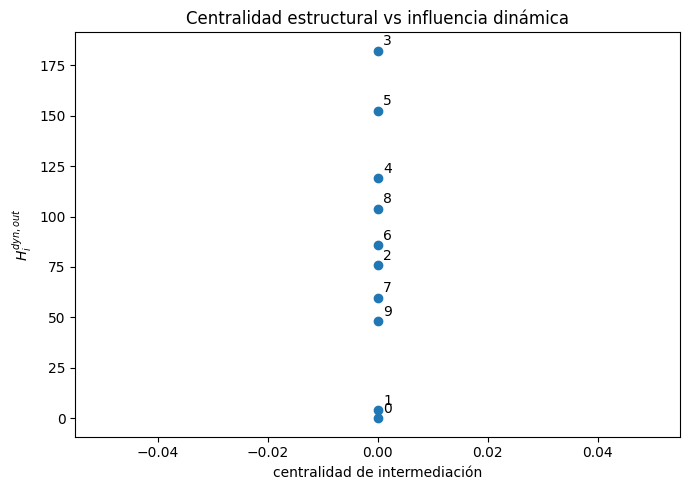

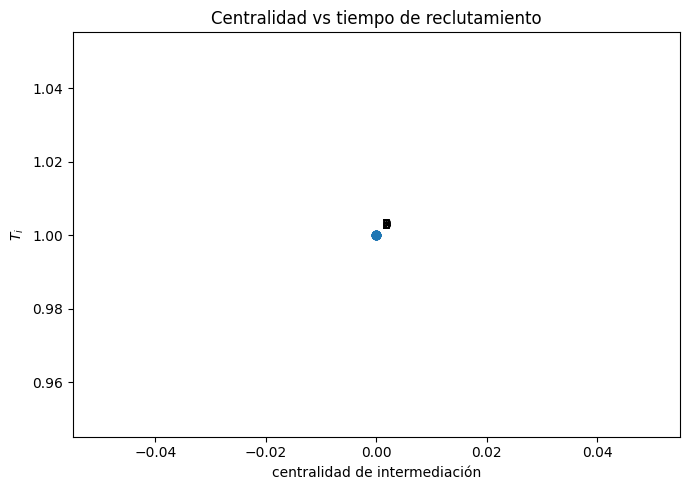

corr(betweenness, T_recruit): (nan, nan)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(analysis_df["betweenness"], analysis_df["H_dyn_out"])
for i, row in analysis_df.iterrows():
    ax.annotate(str(i), (row["betweenness"], row["H_dyn_out"]), xytext=(4,4),
                textcoords="offset points")
ax.set(xlabel="centralidad de intermediación", ylabel=r"$H_i^{dyn,out}$",
       title="Centralidad estructural vs influencia dinámica")
fig.tight_layout()
fig.savefig(FIG_DIR/"centralidad_vs_influencia.png", dpi=200)
plt.show()

mask = np.isfinite(analysis_df["T_recruit"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(analysis_df.loc[mask, "betweenness"],
           analysis_df.loc[mask, "T_recruit"])
for i in analysis_df.index[mask]:
    ax.annotate(str(i),
                (analysis_df.loc[i, "betweenness"], analysis_df.loc[i, "T_recruit"]),
                xytext=(4,4), textcoords="offset points")
ax.set(xlabel="centralidad de intermediación", ylabel=r"$T_i$",
       title="Centralidad vs tiempo de reclutamiento")
fig.tight_layout()
fig.savefig(FIG_DIR/"centralidad_vs_reclutamiento.png", dpi=200)
plt.show()

print("corr(betweenness, T_recruit):",
      safe_corr(analysis_df.betweenness.values, analysis_df.T_recruit.values))


# **Grafo Dinámico 3D**

Cada región del Epileptor tiene tres coordenadas naturales: $x_i(t)$, $z_i(t)$ y su excitabilidad $x_{0,i}$. Las usamos como espacio 3D, así los nodos se mueven con la dinámica y las aristas cambian de grosor según $W_{ij}(t)$.

Las aristas se dibujan de $j$ hacia $i$ (quién influye sobre quién), que es la convención dinámica discutida en la sección 3.

**Aviso:** con $I=3.1$ y $x(0)\approx-1$, todas las regiones saltan a $x\approx1.14$ en $t\approx1$, incluso con $K=0$. Con $x_{th}=1$ el reclutamiento es trivial; conviene revisar umbral, condiciones iniciales o $I$ antes de interpretar $T_i$ y $R(K)$.

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation, PillowWriter

def colores_regiones(x0):
    return np.where(x0 < X0_REFERENCE, "tab:red", "tab:blue")

## **Grafo Estructural 3D**

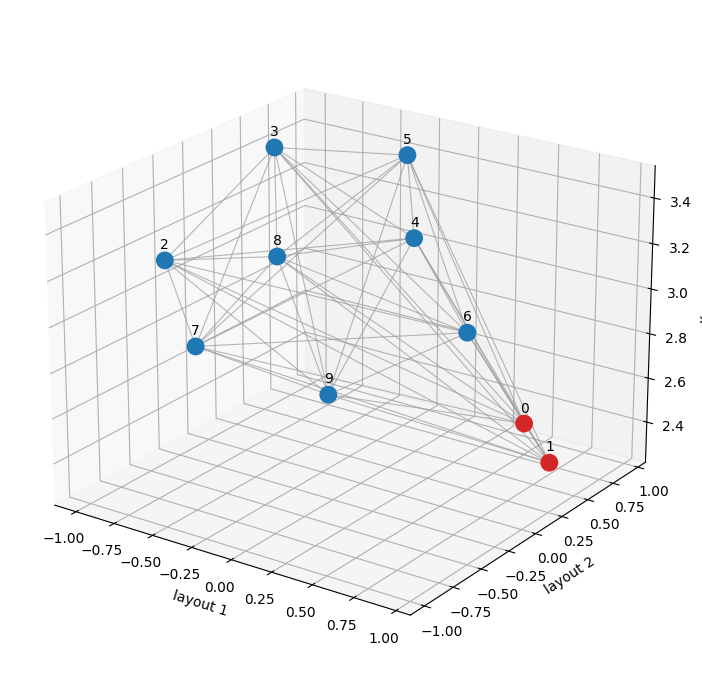

In [ ]:
def layout_3d_por_excitabilidad(x0, seed=SEED):
    G = build_graph(build_adjacency(x0))
    xy = nx.spring_layout(G.to_undirected(), seed=seed, dim=2)
    return np.array([[xy[i][0], xy[i][1], x0[i]] for i in range(len(x0))])

def dibujar_grafo_3d(A, x0, elev=22, azim=-55):
    pos = layout_3d_por_excitabilidad(x0)
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(projection="3d")

    for i, j in zip(*np.nonzero(A)):
        ax.plot(*zip(pos[j], pos[i]), color="0.6", lw=0.8, alpha=0.7)

    ax.scatter(*pos.T, c=colores_regiones(x0), s=140, depthshade=False)
    for i, (a, b, c) in enumerate(pos):
        ax.text(a, b, c + 0.05, str(i), ha="center")

    ax.set(xlabel="layout 1", ylabel="layout 2", zlabel="$x_{0,i}$")
    ax.view_init(elev, azim)
    fig.tight_layout()
    return fig

dibujar_grafo_3d(A, x0).savefig(FIG_DIR / "grafo_3d.png", dpi=150)
plt.show()

## **Grafo en el Espacio de Fases**

Foto del grafo dinámico en un instante: cada nodo está en $(x_i, z_i, x_{0,i})$ y el color y grosor de cada arista siguen $W_{ij}(t)$.

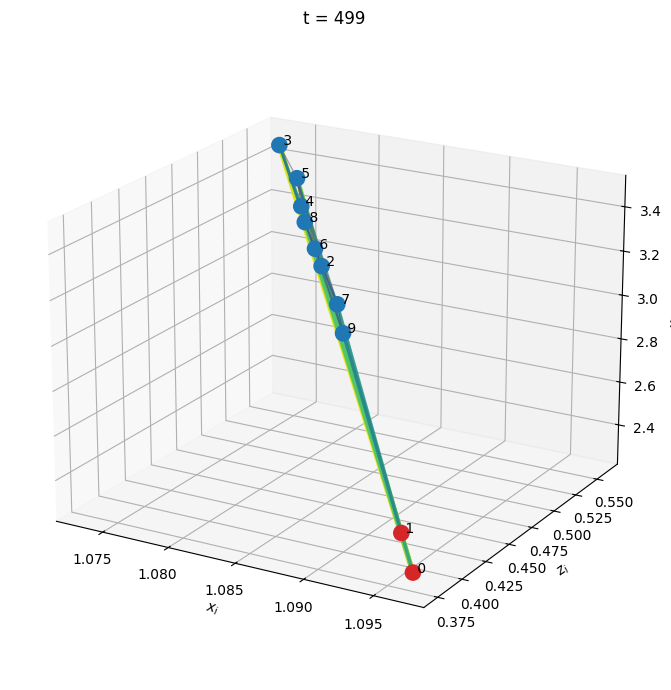

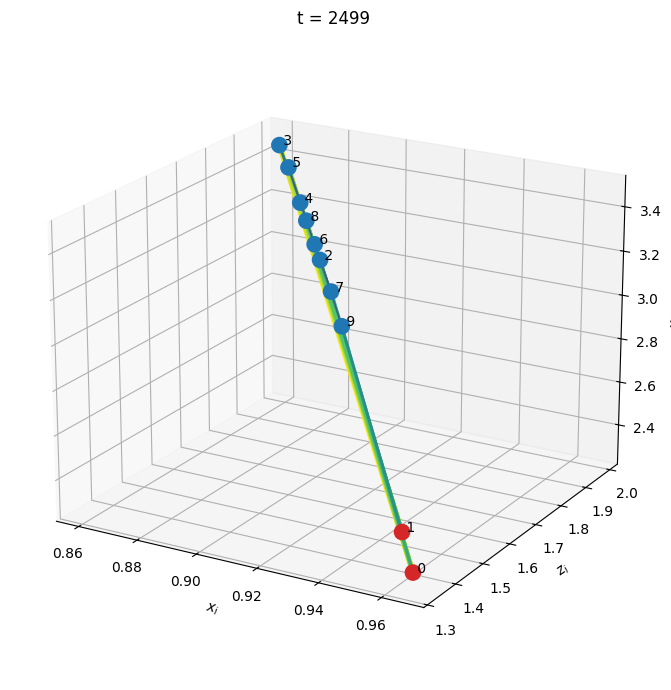

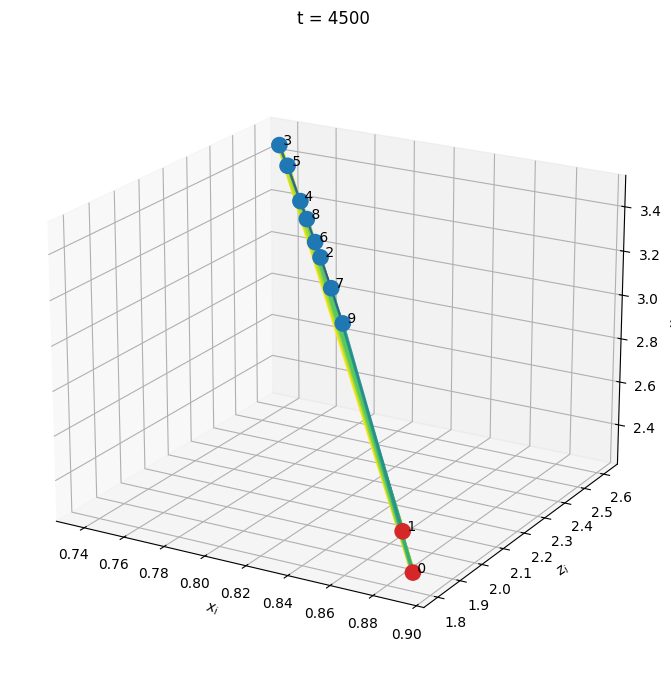

In [ ]:
def dibujar_fases_3d(t, x, z, x0, W, A, frac_tiempo=0.5, elev=20, azim=-60):
    k = int(frac_tiempo * (len(t) - 1))
    pos = np.column_stack([x[:, k], z[:, k], x0])

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(projection="3d")

    wmax = W[k].max() if W[k].max() > 0 else 1.0
    for i, j in zip(*np.nonzero(A)):
        w = W[k, i, j] / wmax
        ax.plot(*zip(pos[j], pos[i]), color=plt.cm.viridis(w),
                lw=0.4 + 3.5 * w, alpha=0.4 + 0.5 * w)

    ax.scatter(*pos.T, c=colores_regiones(x0), s=120, depthshade=False)
    for i, p in enumerate(pos):
        ax.text(*p, f" {i}")

    ax.set(xlabel="$x_i$", ylabel="$z_i$", zlabel="$x_{0,i}$", title=f"t = {t[k]:.0f}")
    ax.view_init(elev, azim)
    fig.tight_layout()
    return fig

for frac in (0.1, 0.5, 0.9):
    dibujar_fases_3d(t, x, z, x0, W_abs, A, frac_tiempo=frac)
    plt.show()

## **Capas Temporales**


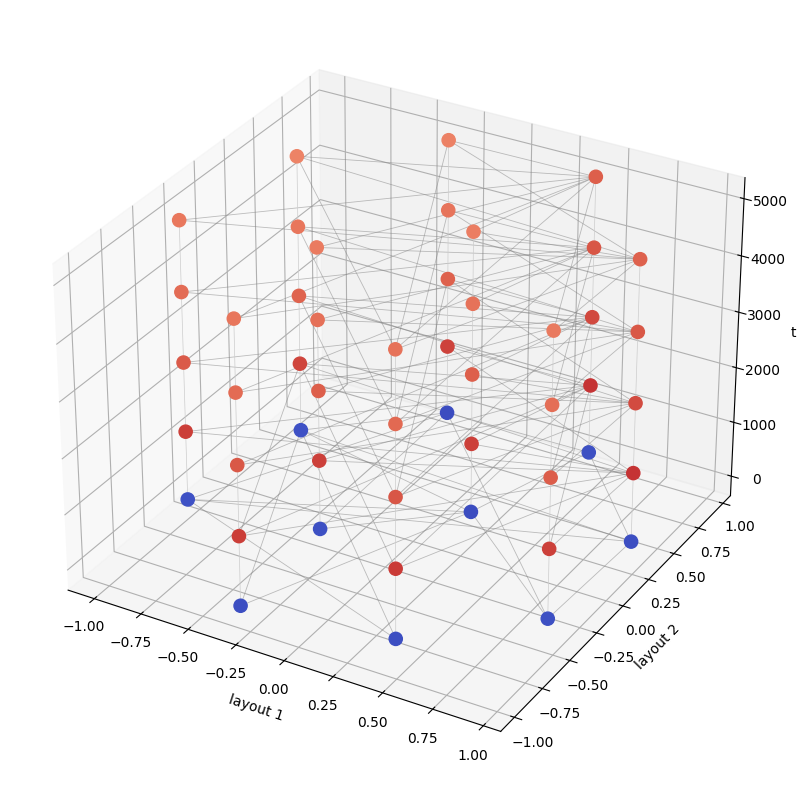

In [ ]:
def dibujar_capas_temporales(t, x, x0, W, A, n_capas=5, umbral_pct=60):
    pos2d = nx.spring_layout(build_graph(A).to_undirected(), seed=SEED)
    xy = np.array([pos2d[i] for i in range(len(x0))])
    idx = np.linspace(0, len(t) - 1, n_capas).astype(int)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")

    for k in idx:
        ax.scatter(xy[:, 0], xy[:, 1], np.full(len(x0), t[k]),
                   c=x[:, k], cmap="coolwarm", vmin=x.min(), vmax=x.max(),
                   s=90, depthshade=False)
        w = W[k][A > 0]
        corte = np.percentile(w, umbral_pct) if w.size else 0
        for i, j in zip(*np.nonzero(A)):
            if W[k, i, j] >= corte:
                ax.plot([xy[j, 0], xy[i, 0]], [xy[j, 1], xy[i, 1]], [t[k]] * 2,
                        color="0.5", lw=0.6, alpha=0.5)

    for i in range(len(x0)):
        ax.plot(np.full(len(idx), xy[i, 0]), np.full(len(idx), xy[i, 1]), t[idx],
                color="0.8", lw=0.5)

    ax.set(xlabel="layout 1", ylabel="layout 2", zlabel="t")
    fig.tight_layout()
    return fig

dibujar_capas_temporales(t, x, x0, W_abs, A)
plt.show()

## **Animación 3D**


In [ ]:
def animar_grafo_3d(t, x, z, x0, W, A, n_frames=60, archivo=FIG_DIR / "grafo_3d.gif"):
    frames = np.linspace(0, len(t) - 1, n_frames).astype(int)
    aristas = list(zip(*np.nonzero(A)))
    wmax = W.max()
    cols = colores_regiones(x0)
    rango = lambda v: (v.min() - 0.1, v.max() + 0.1)

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(projection="3d")

    def dibujar(f):
        ax.cla()
        k = frames[f]
        pos = np.column_stack([x[:, k], z[:, k], x0])
        for i, j in aristas:
            w = W[k, i, j] / wmax
            ax.plot(*zip(pos[j], pos[i]), color=plt.cm.magma(w),
                    lw=0.3 + 3 * w, alpha=0.3 + 0.6 * w)
        ax.scatter(*pos.T, c=cols, s=80, depthshade=False)
        ax.set(xlim=rango(x), ylim=rango(z), zlim=rango(x0),
               xlabel="$x_i$", ylabel="$z_i$", zlabel="$x_{0,i}$", title=f"t = {t[k]:.0f}")
        ax.view_init(20, -60 + 0.8 * f)

    ani = FuncAnimation(fig, dibujar, frames=n_frames)
    ani.save(archivo, writer=PillowWriter(fps=12))
    plt.close(fig)
    return archivo

animar_grafo_3d(t, x, z, x0, W_abs, A, n_frames=60)

PosixPath('figuras/grafo_3d.gif')

## **Versión Interactiva**


In [ ]:
import plotly.graph_objects as go

def grafo_3d_interactivo(t, x, z, x0, W, A, n_frames=40):
    frames_idx = np.linspace(0, len(t) - 1, n_frames).astype(int)
    aristas = list(zip(*np.nonzero(A)))
    cols = np.where(x0 < X0_REFERENCE, "crimson", "royalblue")

    def trazas(k):
        pos = np.column_stack([x[:, k], z[:, k], x0])
        ex, ey, ez = [], [], []
        for i, j in aristas:
            ex += [pos[j, 0], pos[i, 0], None]
            ey += [pos[j, 1], pos[i, 1], None]
            ez += [pos[j, 2], pos[i, 2], None]
        lineas = go.Scatter3d(x=ex, y=ey, z=ez, mode="lines", hoverinfo="skip",
                              line=dict(color="rgba(120,120,120,0.35)", width=2))
        nodos = go.Scatter3d(x=pos[:, 0], y=pos[:, 1], z=pos[:, 2], mode="markers+text",
                             text=[str(i) for i in range(len(x0))],
                             marker=dict(size=7, color=cols))
        return [lineas, nodos]

    fig = go.Figure(data=trazas(frames_idx[0]),
                    frames=[go.Frame(data=trazas(k), name=f"{t[k]:.0f}") for k in frames_idx])
    fig.update_layout(
        scene=dict(xaxis_title="x_i", yaxis_title="z_i", zaxis_title="x0_i"),
        updatemenus=[dict(type="buttons", buttons=[dict(label="▶", method="animate", args=[None])])],
        sliders=[dict(steps=[dict(method="animate", label=f.name, args=[[f.name]])
                             for f in fig.frames])],
        showlegend=False, margin=dict(l=0, r=0, t=30, b=0))
    return fig

fig_pl = grafo_3d_interactivo(t, x, z, x0, W_abs, A)
fig_pl.write_html(str(FIG_DIR / "grafo_3d.html"))
fig_pl.show()

# **Reclutamiento sin Depender de la Grilla**

`first_sustained_crossing` devuelve un tiempo de la grilla `t_eval`. Esta versión interpola el cruce lineal, así $T_i$ no queda atado a `n_samples`.

In [ ]:
def tiempo_de_reclutamiento_continuo(t, x, umbral=1.0, duracion=50.0):
    out = np.full(x.shape[0], np.inf)
    for i in range(x.shape[0]):
        arriba = x[i] > umbral
        k = 0
        while k < len(t):
            if not arriba[k]:
                k += 1
                continue
            s = k
            while k < len(t) and arriba[k]:
                k += 1
            if t[k - 1] - t[s] >= duracion:
                if s > 0:
                    frac = (umbral - x[i, s - 1]) / (x[i, s] - x[i, s - 1])
                    out[i] = t[s - 1] + frac * (t[s] - t[s - 1])
                else:
                    out[i] = t[0]
                break
    return out

T_continuo = tiempo_de_reclutamiento_continuo(t, x, X_THRESHOLD, MIN_DURATION)
print("T_i interpolado:", T_continuo)

T_i interpolado: [0.937  0.9374 0.9364 0.9369 0.9376 0.9367 0.9368 0.9362 0.9371 0.9369]


#  **Perturbación dinámica**

Para una región $i$, se compara el sistema original con una modificación de su estado inicial.

Se define

$$
D_i=\int_0^T\|X^{(i)}(t)-X(t)\|\,dt.
$$

Esta cantidad se interpreta como **sensibilidad dinámica a la perturbación elegida**.


In [ ]:
def perturbation_impact(
    x0, A, K, base_x, base_z,
    node, delta_x=0.05, T=5000.0, n_samples=3000,
    method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
):
    t1, x1, z1, sol1 = simulate(
        x0, A, K, base_x, base_z, T, n_samples,
        method, rtol, atol, max_step
    )

    pert_x = np.array(base_x, copy=True)
    pert_x[node] += delta_x

    t2, x2, z2, sol2 = simulate(
        x0, A, K, pert_x, base_z, T, n_samples,
        method, rtol, atol, max_step
    )

    X1 = np.vstack([x1, z1])
    X2 = np.vstack([x2, z2])
    distance = np.linalg.norm(X2 - X1, axis=0)
    D = np.trapezoid(distance, x=t1)

    return D, t1, distance

D_example, _, _ = perturbation_impact(
    x0, A, BASE_K, x_init_B, z_init_B, node=0, T=2000, n_samples=1500
)
print("D_0 =", D_example)


D_0 = 0.0581492473775406


# 17. Control de acoplamiento: \(A=0\) y \(K>0\)

Se compara:

\[
K=0
\]

con

\[
K>0.
\]

También se puede usar directamente \(A=0\). El objetivo es verificar que el reclutamiento adicional realmente depende del acoplamiento de red y no solamente de la dinámica individual.


In [ ]:
def run_recruitment_experiment(A_use, K, T=5000.0, n_samples=5000,
                                 threshold=X_THRESHOLD, min_duration=MIN_DURATION,
                                 seed=SEED):
    xi, zi = initial_conditions(len(x0), "B", seed)
    tt, xx, zz, ss = simulate(
        x0, A_use, K, xi, zi,
        T=T, n_samples=n_samples,
        method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
    )
    Ti = recruitment_times(tt, xx, threshold, min_duration)
    return {
        "t": tt, "x": xx, "z": zz, "T": Ti,
        "R": recruitment_fraction(Ti, len(x0))
    }

control_K0 = run_recruitment_experiment(A, K=0.0, T=3000, n_samples=3000)
coupled = run_recruitment_experiment(A, K=BASE_K, T=3000, n_samples=3000)

print("R(K=0) =", control_K0["R"])
print("R(K>0) =", coupled["R"])


R(K=0) = 1.0
R(K>0) = 1.0


# **Control de dirección: $A$ vs $A^T$**

Se comparan:

- número/fracción de regiones reclutadas;
- tiempos $T_i$;
- actividad colectiva;
- influencia acumulada;
- hubs dinámicos.


In [ ]:
def compare_directions(K=BASE_K, T=3000.0, n_samples=3000):
    results = {}
    for name, A_use in [("A", A), ("A_T", A.T)]:
        xi, zi = initial_conditions(N, "B", SEED)
        tt, xx, zz, ss = simulate(
            x0, A_use, K, xi, zi,
            T=T, n_samples=n_samples,
            method="DOP853", rtol=1e-8, atol=1e-10, max_step=20.0
        )
        Ti = recruitment_times(tt, xx, X_THRESHOLD, MIN_DURATION)
        W, _ = dynamic_weight_matrices(xx, A_use, K)
        Icum = cumulative_influence(tt, W)
        results[name] = {
            "t": tt, "x": xx, "z": zz,
            "T": Ti, "R": recruitment_fraction(Ti, N),
            "I": Icum,
            "H_out": Icum.sum(axis=1),
            "H_in": Icum.sum(axis=0)
        }
    return results

direction_results = compare_directions()
print("R(A)   =", direction_results["A"]["R"])
print("R(A^T) =", direction_results["A_T"]["R"])


R(A)   = 1.0
R(A^T) = 1.0


#  **Estudio del acoplamiento $K$**


,K,n_recruited_healthy,R
0,0.00,8,1.0
1,0.02,8,1.0
2,0.05,8,1.0
3,0.10,8,1.0
4,0.20,8,1.0
5,0.50,8,1.0


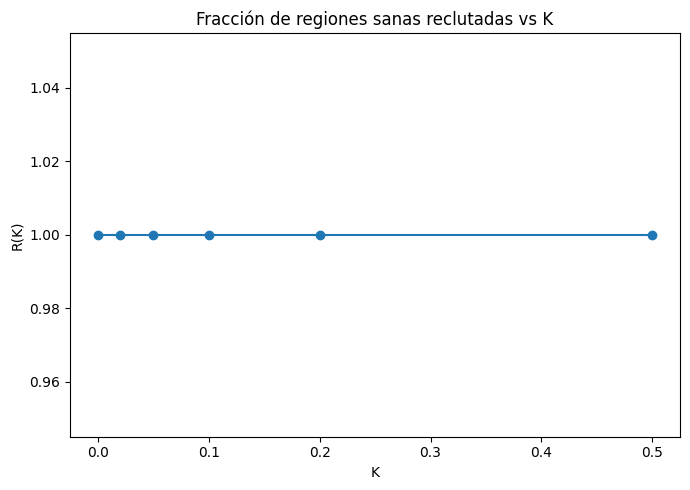

In [ ]:
def sweep_K(K_values, T=3000.0, n_samples=3000, seed=SEED):
    rows = []
    for K in K_values:
        result = run_recruitment_experiment(
            A, K, T=T, n_samples=n_samples, seed=seed
        )
        Ti = result["T"]
        healthy = np.arange(2, N)
        n_recruited = np.isfinite(Ti[healthy]).sum()
        rows.append({
            "K": K,
            "n_recruited_healthy": int(n_recruited),
            "R": n_recruited / max(1, len(healthy))
        })
    return pd.DataFrame(rows)

K_VALUES = np.array([0.0, 0.02, 0.05, 0.1, 0.2, 0.5])
K_results = sweep_K(K_VALUES, T=2000, n_samples=2000)
display(K_results)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(K_results["K"], K_results["R"], marker="o")
ax.set(xlabel="K", ylabel="R(K)", title="Fracción de regiones sanas reclutadas vs K")
fig.tight_layout()
fig.savefig(FIG_DIR/"reclutamiento_vs_K.png", dpi=200)
plt.show()


# 20. Escalamiento con $N$



In [ ]:
def one_N_experiment(N_value, K=BASE_K, seed=SEED,
                      T=2000.0, n_samples=1500,
                      normalized=False):
    x0_N = generate_x0(N_value, seed)
    A_N = build_adjacency(x0_N)

    K_eff = K / N_value if normalized else K
    xi, zi = initial_conditions(N_value, "B", seed)

    tt, xx, zz, ss = simulate(
        x0_N, A_N, K_eff, xi, zi,
        T=T, n_samples=n_samples,
        method="DOP853", rtol=1e-7, atol=1e-9, max_step=20.0
    )

    Ti = recruitment_times(tt, xx, X_THRESHOLD, MIN_DURATION)
    healthy = np.arange(2, N_value)
    R = np.isfinite(Ti[healthy]).mean() if len(healthy) else np.nan

    return {
        "N": N_value,
        "seed": seed,
        "R": R,
        "mean_T_healthy": np.nanmean(
            np.where(np.isfinite(Ti[healthy]), Ti[healthy], np.nan)
        ) if len(healthy) else np.nan,
        "n_edges": int(A_N.sum()),
        "K_effective": K_eff
    }

# Ejemplo pequeño
N_scaling_example = [2, 5, 10]
scaling_rows = [
    one_N_experiment(nv, K=BASE_K, seed=SEED, T=1000, n_samples=1000)
    for nv in N_scaling_example
]
scaling_df = pd.DataFrame(scaling_rows)
display(scaling_df)


,N,seed,R,mean_T_healthy,n_edges,K_effective
0,2,42,NaN,NaN,1,0.1
1,5,42,1.0,1.001001,10,0.1
2,10,42,1.0,1.001001,45,0.1


# **Acoplamiento normalizado vs no normalizado**

### No normalizado

$$
K\sum_jA_{ij}(x_j-x_i).
$$

### Normalizado

$$
\frac{\kappa}{N}\sum_jA_{ij}(x_j-x_i).
$$



In [ ]:
def compare_normalization(N_values=(5, 10, 20), kappa=BASE_K,
                           T=1000.0, n_samples=800):
    rows = []
    for nv in N_values:
        for normalized in [False, True]:
            out = one_N_experiment(
                nv, K=kappa, seed=SEED,
                T=T, n_samples=n_samples,
                normalized=normalized
            )
            out["normalized"] = normalized
            rows.append(out)
    return pd.DataFrame(rows)

normalization_df = compare_normalization()
display(normalization_df)


,N,seed,R,mean_T_healthy,n_edges,K_effective,normalized
0,5,42,1.0,1.251564,10,0.100,False
1,5,42,1.0,1.251564,10,0.020,True
2,10,42,1.0,1.251564,45,0.100,False
3,10,42,1.0,1.251564,45,0.010,True
4,20,42,1.0,1.251564,190,0.100,False
5,20,42,1.0,1.251564,190,0.005,True


In [ ]:
def coupling_network(x, A, K):
    return K * np.sum(A[:, :, None] * (x[None, :, :] - x[:, None, :]), axis=1)

def coupling_mean_field(x, kappa):
    m = x.mean(axis=0)
    return kappa * (m[None, :] - x)

network_coupling = coupling_network(x, A, BASE_K)
meanfield_coupling = coupling_mean_field(x, BASE_K)
relative_error_mf = (
    np.linalg.norm(network_coupling - meanfield_coupling)
    / max(np.linalg.norm(network_coupling), 1e-14)
)
print("Error relativo global red vs campo medio:", relative_error_mf)


Error relativo global red vs campo medio: 0.9281648233061075
